In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

### 2. Create a Toy Dataset

In [2]:
np.random.seed(42)
n_samples = 500

X1 = np.linspace(1, 10, n_samples).reshape(-1, 1)
X2 = np.linspace(5, 15, n_samples).reshape(-1, 1)
X3 = np.linspace(24, 35, n_samples).reshape(-1, 1)
X = np.hstack((X1, X2, X3))


In [3]:
y = 2 * X[:, 0:1] + 3 * X[:, 1:2] + 4 * X[:, 2:3] + 5

normal_noise = np.random.normal(0, 2, (n_samples, 1))
hetero_noise = np.random.normal(0, 2, (n_samples, 1)) * (1.5 * X[:, 0:1])
y_noisy = y + normal_noise + hetero_noise

### 3. Fit Standard Linear Regression

In [4]:
model_raw = LinearRegression()
model_raw.fit(X, y_noisy)
y_pred_raw = model_raw.predict(X)

### 4. Feature Transform (Log) and Fit Linear Regression

In [5]:
y_log = np.log(y_noisy - y_noisy.min() + 1)
model_transformed = LinearRegression()
model_transformed.fit(X, y_log)
y_pred_transformed = np.exp(model_transformed.predict(X)) + y_noisy.min() - 1

### 5. Visualization

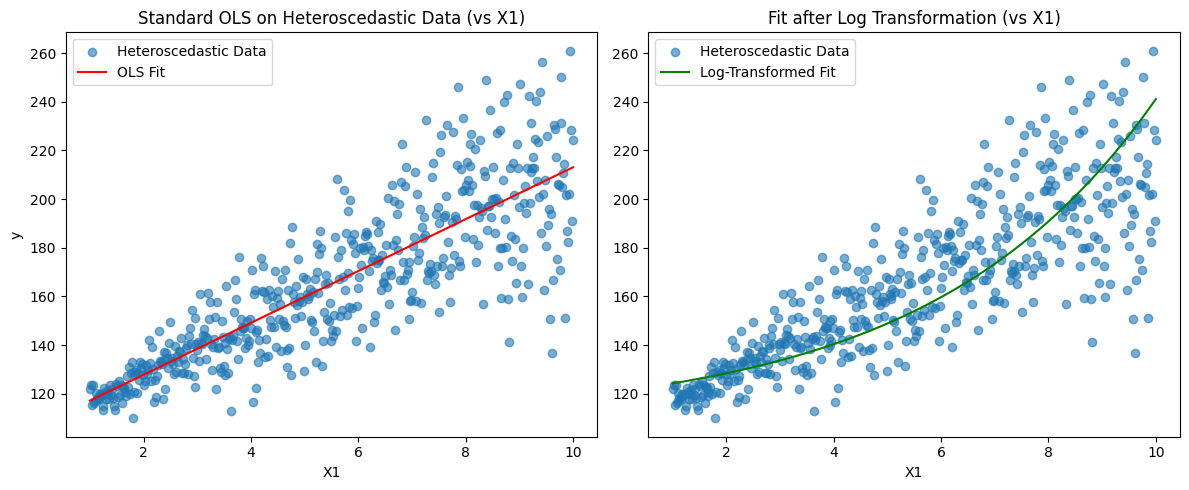

In [6]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], y_noisy, alpha=0.6, label='Heteroscedastic Data')
plt.plot(X[:, 0], y_pred_raw, color='red', label='OLS Fit')
plt.title("Standard OLS on Heteroscedastic Data (vs X1)")
plt.xlabel("X1")
plt.ylabel("y")
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], y_noisy, alpha=0.6, label='Heteroscedastic Data')
plt.plot(X[:, 0], y_pred_transformed, color='green', label='Log-Transformed Fit')
plt.title("Fit after Log Transformation (vs X1)")
plt.xlabel("X1")
plt.legend()

plt.tight_layout()
plt.show()

### 6. Evaluate Model Performance (MSE)
The results suggest that while the transformation might have addressed the heteroscedasticity, the distortion introduced by the inverse exponential transformation outweighed the benefits in terms of MSE, or that the original model was already performing reasonably well in terms of minimizing the MSE in the original scale.

In [7]:
print(f"Original MSE: {mean_squared_error(y_noisy, y_pred_raw):.4f}")
print(f"Transformed MSE: {mean_squared_error(y_noisy, y_pred_transformed):.4f}")

Original MSE: 308.9274
Transformed MSE: 420.2828
